# Packages

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, GroupKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import SGDClassifier

# Data preprocessing

## Merging dataframes

In [50]:
df_admission = pd.read_csv('../Data/ED_admission.csv')
df_admission.columns

Index(['triage_code', 'PatientCode', 'DischargeFromED', 'Foreigners', 'gender',
       'age', 'marital_Status', 'ResidentDate_year', 'ResidentDate_month',
       'ResidentDate_day', 'ResidentDate_weekday', 'ResidentDate_hour',
       'DischargeDate_year', 'DischargeDate_month', 'DischargeDate_day',
       'DischargeDate_weekday', 'DischargeDate_hour', 'StatusOnDischarge',
       'KindRef', 'IsGlobal', 'AccompainerRelation_id', 'ResidentDay',
       'service_count_action', 'service_count_instrument', 'service_count_lab',
       'service_count_graphy'],
      dtype='str')

In [51]:
# Selecting useful columns from the administration data that are absent from the triage one
cols_admission = [
    'triage_code',
    'PatientCode',      # Mandatory to group by patient during train/test split
    'DischargeFromED',  # Target
    'Foreigners',
    'marital_Status',
    'AccompainerRelation_id'
]

In [52]:
df_triage = pd.read_csv('../Data/ED_triage.csv')
df_triage.columns

Index(['triage_code', 'gender', 'age', 'admission_year', 'admission_month',
       'admission_day', 'admission_weekday', 'admission_hour', 'kindref',
       'ChiefComplaint', 'explainer_id', 'NeedFastExecute', 'CriticalStatus',
       'StuporStatus', 'PainGrade', 'MentalDistress', 'MaterialDistress',
       'Source', 'BlooddpressurSystol', 'BlooddpressurDiastol', 'PulseRate',
       'RespiratoryRate', 'Temperature', 'O2Saturation', 'AVPU', 'TriageGrade',
       'operational_patient', 'ref_specialist'],
      dtype='str')

In [53]:
# Selecting variables known during trial
cols_triage = [
    'triage_code',
    'gender', 'age', 'admission_year', 'admission_month', 'admission_day', 'admission_weekday', 'admission_hour', # Demographic and temporal context
    'explainer_id', 'ChiefComplaint', 'kindref', 'Source', # Reason for and manner of arrival
    'TriageGrade', 'CriticalStatus', 'NeedFastExecute', 'StuporStatus', 'PainGrade', 'MentalDistress', 'MaterialDistress', 'AVPU', # Clinical scores and gravity at triage
    'BlooddpressurSystol', 'BlooddpressurDiastol', 'PulseRate', 'RespiratoryRate', 'Temperature', 'O2Saturation' # Vital Signs
]

In [54]:
df = pd.merge(df_admission[cols_admission], df_triage[cols_triage], on='triage_code', how='inner')

## EDA

In [55]:
df.rename(columns={'BlooddpressurSystol' : 'BloodpressurSystol',
                   'BlooddpressurDiastol' : 'BloodpressurDiastol'}, 
                   inplace=True)

C:\Users\PC\AppData\Local\Temp\ipykernel_13612\1164776113.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'BlooddpressurSystol' : 'BloodpressurSystol',


In [56]:
# Defining columns groups
num_vitals   = ['BloodpressurSystol', 'BloodpressurDiastol', 'PulseRate', 'RespiratoryRate', 'O2Saturation']
binary_cols  = ['NeedFastExecute', 'CriticalStatus', 'StuporStatus', 'MentalDistress', 'MaterialDistress']
nominal_cols = ['kindref', 'Source', 'AVPU', 'marital_Status', 'AccompainerRelation_id']

# age, admission_weekday, admission_hour, TriageGrade, PainGrade are already numerical so no need to encode them

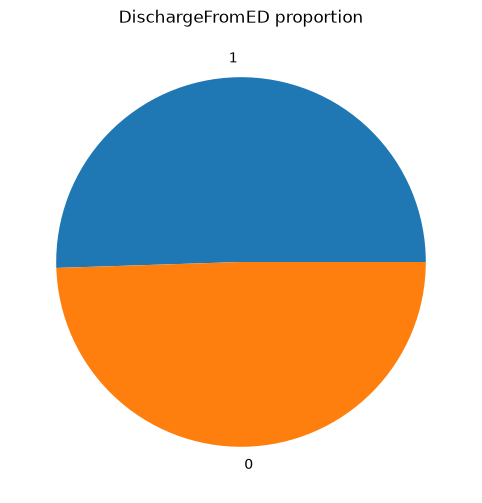

In [57]:
plt.figure(figsize=(6, 6))

y_prop = df['DischargeFromED'].value_counts(normalize=True)
plt.pie(y_prop, labels = y_prop.index)

plt.title('DischargeFromED proportion')
plt.show()

Good news : classes for ``DischargeFromED`` are balanced.

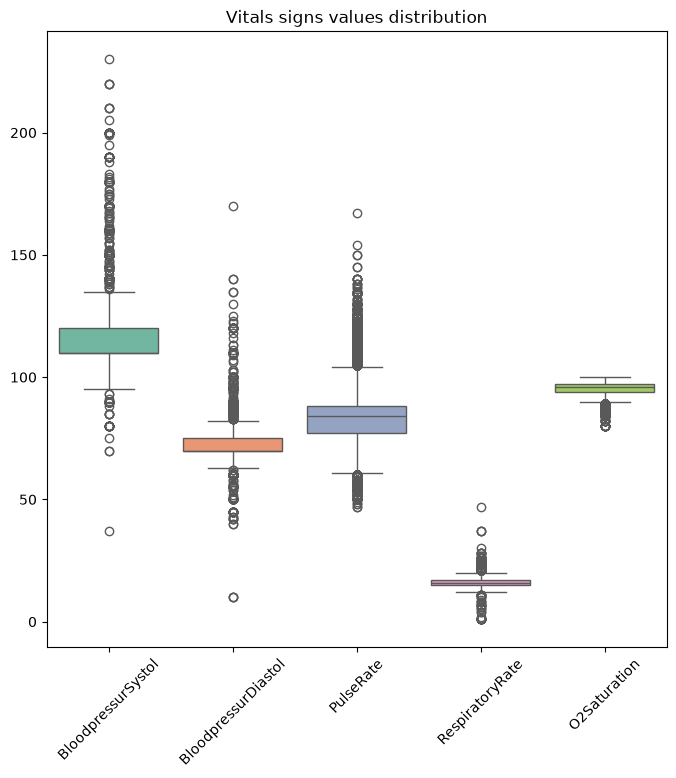

In [58]:
plt.figure(figsize=(8, 8))

sns.boxplot(data=df[num_vitals], palette='Set2')

plt.xticks(rotation=45)
plt.title('Vitals signs values distribution')
plt.show()

We observe physiological values impossible to get from any alive patient at triage (e.g. near-0 respiratory-rate or diastolic pressure under 10 mmHg). Thus, they probably are artifacts or typing error. We are converting them to NaN values to not falsify median calculus or model learning. Possible physiological values are described in the cell below.

In [59]:
def clean_vital_signs(data: pd.DataFrame) -> pd.DataFrame:
    df_clean = data.copy()
    
    # Respiratory rate (< 6 = apnoea/not measured, > 60 = artefact)
    df_clean.loc[~df_clean['RespiratoryRate'].between(6, 60), 'RespiratoryRate'] = np.nan

    # Cardiac frequency (30-220 range)
    df_clean.loc[~df_clean['PulseRate'].between(30, 220), 'PulseRate'] = np.nan

    # Oxygen saturation (50-100 range)
    df_clean.loc[~df_clean['O2Saturation'].between(50, 100), 'O2Saturation'] = np.nan

    # Blood pressure (sys : 50-260 / dia : 30-140)
    df_clean.loc[~df_clean['BloodpressurSystol'].between(50, 260), 'BloodpressurSystol'] = np.nan
    df_clean.loc[~df_clean['BloodpressurDiastol'].between(30, 140), 'BloodpressurDiastol'] = np.nan

    # Systolic/diastolic inconsistency (removing >15 diff)
    incoherent = (df_clean['BloodpressurSystol'] - df_clean['BloodpressurDiastol']) < 15
    df_clean.loc[incoherent, ['BloodpressurSystol', 'BloodpressurDiastol']] = np.nan

    return df_clean

df = clean_vital_signs(df)

In [60]:
df.isnull().sum()

triage_code                    0
PatientCode                    0
DischargeFromED                0
Foreigners                     0
marital_Status                19
AccompainerRelation_id       790
gender                         0
age                            0
admission_year                 0
admission_month                0
admission_day                  0
admission_weekday              0
admission_hour                 0
explainer_id              109285
ChiefComplaint                 0
kindref                        0
Source                     87511
TriageGrade                    0
CriticalStatus             10376
NeedFastExecute                0
StuporStatus               10376
PainGrade                  10312
MentalDistress             10376
MaterialDistress           10376
AVPU                       90509
BloodpressurSystol        118894
BloodpressurDiastol       118595
PulseRate                 108294
RespiratoryRate           110100
Temperature               143377
O2Saturati

We have to handle missing values for the vital signs. For the vital signs, we will later fill them with the median and create a new column. I chosed this method not to choose an arbitrary value too far away from the physiological one, thus disturbing certain models. The missing-value indicators are created here, but the median is only computed on the training set after the train/test split to avoid data leakage. For the pain scale, I just filled with ``-1`` as the scale is 0-10 anyway.

In [61]:
# Vital signs (new column only, NaN are kept: the median is filled after the split)
for col in num_vitals:
    df[f'{col}_missing'] = df[col].isna().astype(int)

# Filling pain scale
df['PainGrade'] = df['PainGrade'].fillna(-1)

# Binary indicators
df['triage_incomplete'] = df[binary_cols].isna().any(axis=1).astype(int)
df[binary_cols] = df[binary_cols].fillna(0).astype(int)

# Gender
df['gender'] = df['gender'].str.strip().str.lower().map({'male': 1, 'female': 0})
assert df['gender'].notna().all(), df['gender'].unique()
df['gender'] = df['gender'].astype(int)

# Foreigners
df['Foreigners'] = df['Foreigners'].str.strip().str.lower().map({'yes': 1, 'no': 0})
assert df['Foreigners'].notna().all(), df['Foreigners'].unique()
df['Foreigners'] = df['Foreigners'].astype(int)

<Figure size 800x600 with 0 Axes>

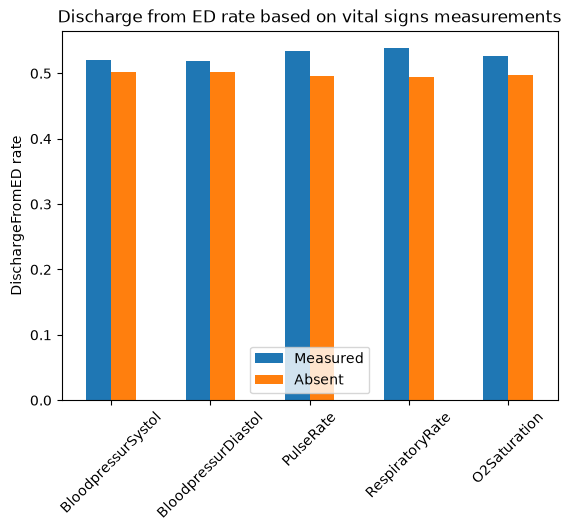

In [62]:
plt.figure(figsize=(8, 6))

missing_rates = {col: df.groupby(f"{col}_missing")["DischargeFromED"].mean() for col in num_vitals}
pd.DataFrame(missing_rates).T.rename(columns={0: "Measured", 1: "Absent"}).plot.bar()

plt.xticks(rotation=45)
plt.ylabel("DischargeFromED rate")
plt.title('Discharge from ED rate based on vital signs measurements')
plt.show()

Discharge rate does not change too much if the vital signs are measured or not. ``_missing`` column will probably not be very useful for predictions.

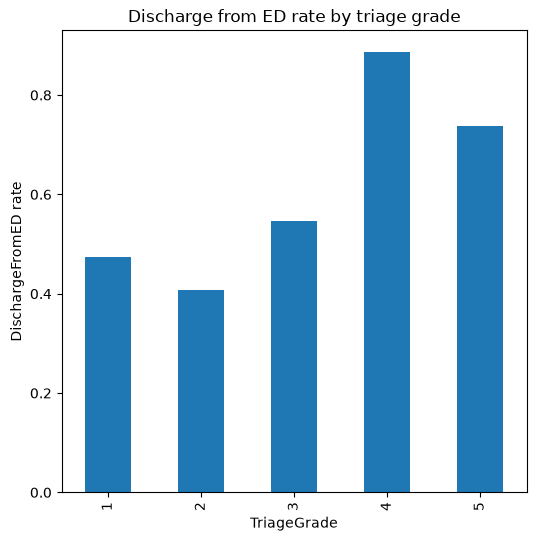

In [63]:
plt.figure(figsize=(6, 6))

df.groupby("TriageGrade")["DischargeFromED"].mean().plot.bar()

plt.ylabel("DischargeFromED rate")
plt.title('Discharge from ED rate by triage grade')
plt.show()

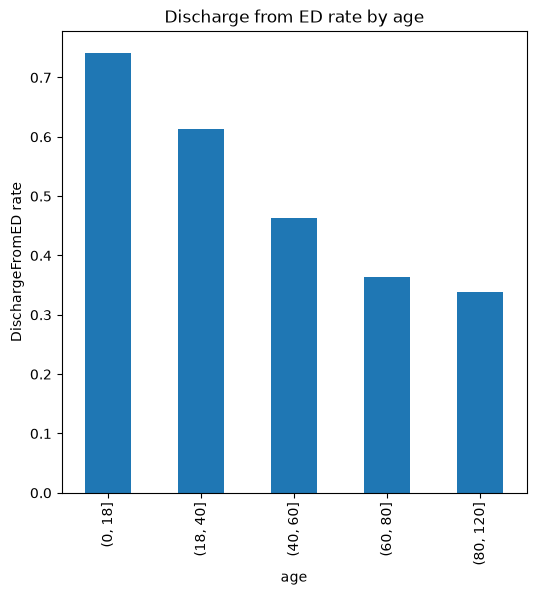

In [64]:
plt.figure(figsize=(6, 6))

df.groupby(pd.cut(df["age"], bins=[0, 18, 40, 60, 80, 120]))["DischargeFromED"].mean().plot.bar()

plt.ylabel("DischargeFromED rate")
plt.title('Discharge from ED rate by age')
plt.show()

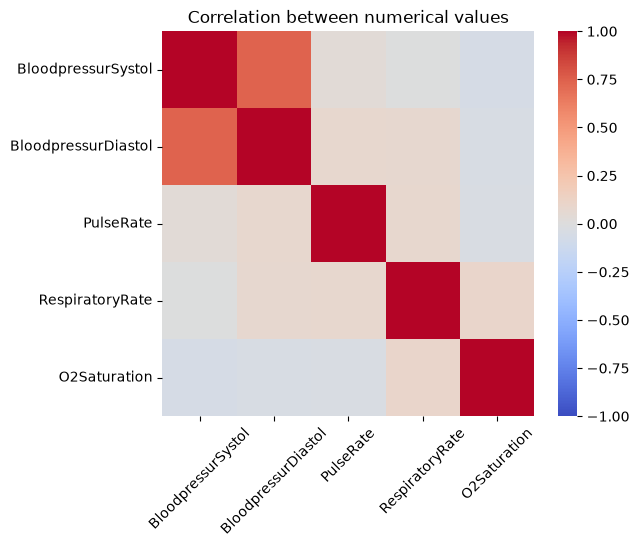

In [65]:
plt.figure(figsize=(6, 5))

sns.heatmap(df[num_vitals].corr(), cmap = 'coolwarm', vmin = -1, vmax = 1)

plt.xticks(rotation=45)
plt.title('Correlation between numerical values')
plt.show()

Little correlations are observed between numerical values. Great news to avoid redundancy. The only high correlations are between the systolic and diastolic pressures.

## Encoding variables

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 143516 entries, 0 to 143515
Data columns (total 37 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   triage_code                  143516 non-null  int64  
 1   PatientCode                  143516 non-null  int64  
 2   DischargeFromED              143516 non-null  int64  
 3   Foreigners                   143516 non-null  int64  
 4   marital_Status               143497 non-null  float64
 5   AccompainerRelation_id       142726 non-null  float64
 6   gender                       143516 non-null  int64  
 7   age                          143516 non-null  int64  
 8   admission_year               143516 non-null  int64  
 9   admission_month              143516 non-null  int64  
 10  admission_day                143516 non-null  int64  
 11  admission_weekday            143516 non-null  int64  
 12  admission_hour               143516 non-null  int64  
 13  explainer_

In [67]:
df = df.drop(columns=['Temperature']) #so many missing values

In [68]:
df['explainer_missing'] = df['explainer_id'].isna().astype(int)

# are the missing values due to bad practice on certain years?
print(df.groupby('admission_year')['explainer_missing'].mean())

# are the NaN linked to the target?
print(df.groupby('explainer_missing')['DischargeFromED'].mean())

# previous modalities weigth
print(df['explainer_id'].value_counts(dropna=False).head(15))

admission_year
2017    0.000000
2018    0.704453
2019    1.000000
2020    1.000000
2021    1.000000
2022    1.000000
Name: explainer_missing, dtype: float64
explainer_missing
0    0.464170
1    0.517948
Name: DischargeFromED, dtype: float64
explainer_id
NaN     109285
3.0      19517
2.0       9685
4.0       4505
1.0        514
5.0          1
6.0          1
7.0          1
8.0          1
9.0          1
10.0         1
11.0         1
12.0         1
13.0         1
14.0         1
Name: count, dtype: int64


In [69]:
df = df.drop(columns=['explainer_id']) # the variable is not a caracteristic from the patient, just a field the hospital did not filled

In [70]:
df['ChiefComplaint'].nunique()

896

The ``ChiefComplaint`` values correspond to the International Classification of Diseases: ICD-10. Since 896 codes is obviously far too many, we’ll just look at the first letter. This will give us about 15-20 categories, which is much easier to interpret.

In [71]:
# Categorical data
df['ChiefComplaint_category'] = df['ChiefComplaint'].str[0]

for col in nominal_cols:
    df[col] = df[col].astype('string').fillna('Unknown')

df = pd.get_dummies(
    df,
    columns=nominal_cols + ['ChiefComplaint_category'],
    prefix={
        'kindref': 'kindref',
        'Source': 'source',
        'AVPU': 'avpu',
        'marital_Status': 'marital',
        'AccompainerRelation_id': 'accomp',
        'ChiefComplaint_category': 'complaint',
    },
    drop_first=True,
    dtype=int,
)

``num_general`` has no missing values so I'm directling handling ``cat_cols``

In [72]:
# Features and target
X = df.drop(columns=['triage_code', 'PatientCode', 'DischargeFromED', 'ChiefComplaint'])
y = df['DischargeFromED']
groups = df['PatientCode']

In [73]:
# Train/test split grouped by patient
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])

# Insights before trying models

Regarding ``DischargeFromED``, patients who are discharged directly from the ED (``DischargeFromED`` = 1), while the second group consists of patients who are transferred to a ward and later discharged from there (``DischargeFromED`` = 0).

Additionally, ``ChiefComplaint`` is described as the reason of consultation declared by the patient, later converted in CIM-10 terms. The risk of a data leakage is low, provided that the coders have merely converted the reason for the consultation into a code. The article does not state whether they were able to draw on the full medical record, including the final diagnosis. Thus, I'll try using models both with and without this variable.

In [74]:
X_train_dp_CC = X_train.drop(columns = ['complaint_3', 'complaint_6', 'complaint_A', 'complaint_B',
       'complaint_C', 'complaint_D', 'complaint_E', 'complaint_F',
       'complaint_G', 'complaint_H', 'complaint_I', 'complaint_J',
       'complaint_K', 'complaint_L', 'complaint_M', 'complaint_N',
       'complaint_O', 'complaint_P', 'complaint_Q', 'complaint_R',
       'complaint_S', 'complaint_T', 'complaint_U', 'complaint_V',
       'complaint_W', 'complaint_X', 'complaint_Y', 'complaint_Z'])

X_test_dp_CC = X_test.drop(columns = ['complaint_3', 'complaint_6', 'complaint_A', 'complaint_B',
       'complaint_C', 'complaint_D', 'complaint_E', 'complaint_F',
       'complaint_G', 'complaint_H', 'complaint_I', 'complaint_J',
       'complaint_K', 'complaint_L', 'complaint_M', 'complaint_N',
       'complaint_O', 'complaint_P', 'complaint_Q', 'complaint_R',
       'complaint_S', 'complaint_T', 'complaint_U', 'complaint_V',
       'complaint_W', 'complaint_X', 'complaint_Y', 'complaint_Z'])

# Models

## Dummy classifier

c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     14247
           1       0.50      1.00      0.67     14452

    accuracy                           0.50     28699
   macro avg       0.25      0.50      0.33     28699
weighted avg       0.25      0.50      0.34     28699



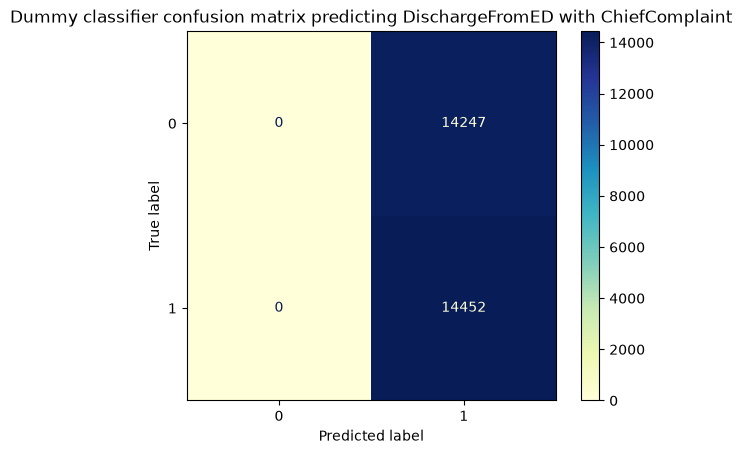

In [75]:
# Model
dc =  DummyClassifier(strategy='most_frequent', random_state=None, constant=None)

# Training
dc.fit(X_train, y_train)

# Prediction
y_pred = dc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
dc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
dc_cm.plot(cmap = 'YlGnBu')
plt.title('Dummy classifier confusion matrix predicting DischargeFromED with ChiefComplaint')
plt.show()

c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\PC\Desktop\ML\ER-predicting-length-of-stay\Code\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this b

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     14247
           1       0.50      1.00      0.67     14452

    accuracy                           0.50     28699
   macro avg       0.25      0.50      0.33     28699
weighted avg       0.25      0.50      0.34     28699



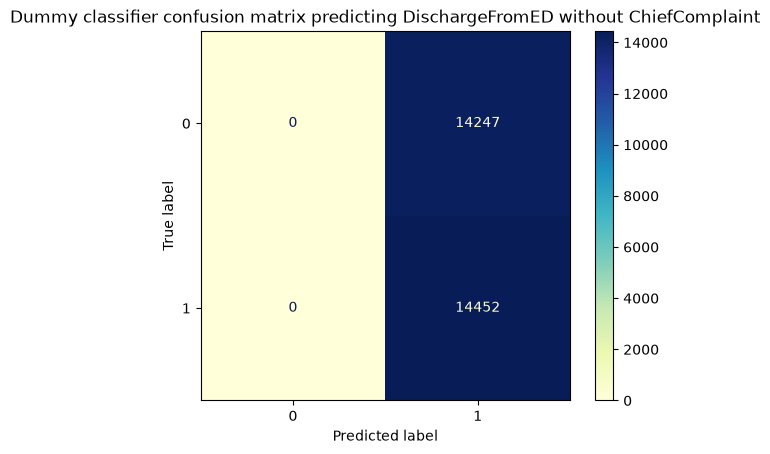

In [76]:
# Model
dc =  DummyClassifier(strategy='most_frequent', random_state=None, constant=None)

# Training
dc.fit(X_train_dp_CC, y_train)

# Prediction
y_pred = dc.predict(X_test_dp_CC)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
dc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
dc_cm.plot(cmap = 'YlGnBu')
plt.title('Dummy classifier confusion matrix predicting DischargeFromED without ChiefComplaint')
plt.show()

## SGD Classifier

              precision    recall  f1-score   support

           0       0.77      0.77      0.77     14247
           1       0.77      0.77      0.77     14452

    accuracy                           0.77     28699
   macro avg       0.77      0.77      0.77     28699
weighted avg       0.77      0.77      0.77     28699



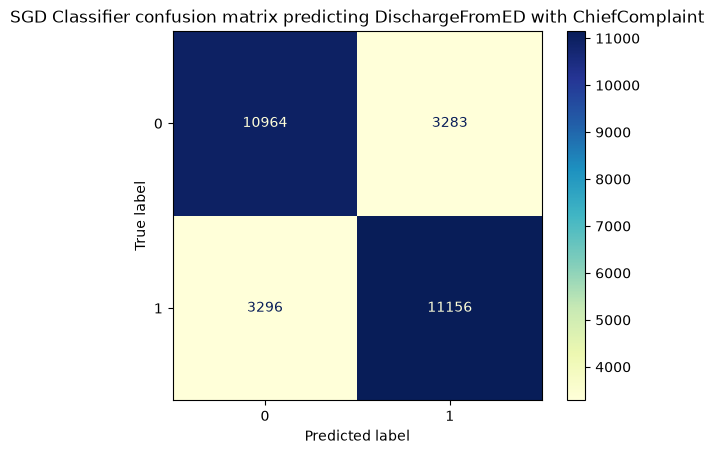

In [77]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train, y_train)

# Prediction
y_pred = sgdc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED with ChiefComplaint')
plt.show()

              precision    recall  f1-score   support

           0       0.72      0.78      0.75     14247
           1       0.77      0.71      0.74     14452

    accuracy                           0.74     28699
   macro avg       0.75      0.74      0.74     28699
weighted avg       0.75      0.74      0.74     28699



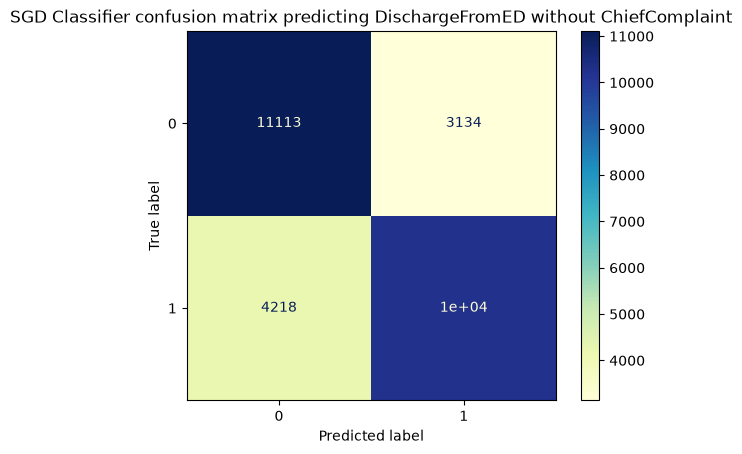

In [78]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(loss="log_loss", max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train_dp_CC, y_train)

# Prediction
y_pred = sgdc.predict(X_test_dp_CC)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED without ChiefComplaint')
plt.show()

As there is only a 4 point difference between the two SGD classifiers, there is little chance of a data leakage. The thing is we don't have access to the CIM-10 terms right away. If needed, we could consider automatically convert the free text to CIM-10. Though, a limit to keep in minde is it is not a guarantee it would be the same as the encoders.

In [79]:
pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                     SGDClassifier(random_state=42, max_iter=2000, tol=1e-3))

param_grid = {
    "sgdclassifier__alpha": [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "sgdclassifier__loss": ["log_loss", "hinge"],
    "sgdclassifier__penalty": ["l2", "l1", "elasticnet"],
}

search = GridSearchCV(pipe, param_grid, cv=GroupKFold(n_splits=5),
                      scoring="roc_auc", n_jobs=-1)

search.fit(X_train, y_train, groups=groups.iloc[train_idx])

print(search.best_params_, search.best_score_)

{'sgdclassifier__alpha': 0.001, 'sgdclassifier__loss': 'log_loss', 'sgdclassifier__penalty': 'l1'} 0.8362859625541779


              precision    recall  f1-score   support

           0       0.76      0.78      0.77     14247
           1       0.78      0.76      0.77     14452

    accuracy                           0.77     28699
   macro avg       0.77      0.77      0.77     28699
weighted avg       0.77      0.77      0.77     28699



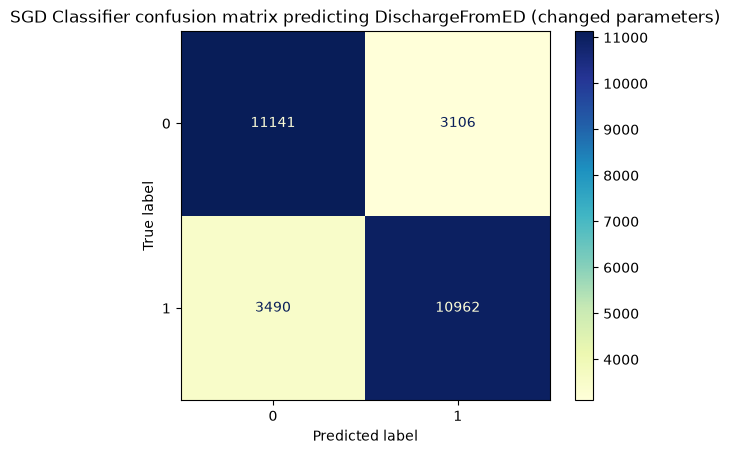

In [80]:
# Model
sgdc = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    SGDClassifier(penalty='l1', alpha=0.001, loss='log_loss', max_iter=1000, tol=1e-3, random_state=42)
)

# Training
sgdc.fit(X_train, y_train)

# Prediction
y_pred = sgdc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
sgdc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
sgdc_cm.plot(cmap = 'YlGnBu')
plt.title('SGD Classifier confusion matrix predicting DischargeFromED (changed parameters)')
plt.show()

## HistGradientBoostingClassifier

              precision    recall  f1-score   support

           0       0.79      0.86      0.82     14247
           1       0.85      0.78      0.81     14452

    accuracy                           0.82     28699
   macro avg       0.82      0.82      0.82     28699
weighted avg       0.82      0.82      0.82     28699



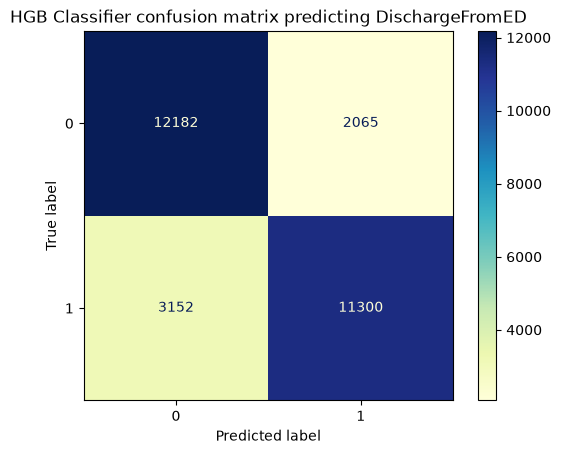

In [81]:
# Model
hgbc = HistGradientBoostingClassifier()

# Training
hgbc.fit(X_train, y_train)

# Prediction
y_pred = hgbc.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
hgbc_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
hgbc_cm.plot(cmap = 'YlGnBu')
plt.title('HGB Classifier confusion matrix predicting DischargeFromED')
plt.show()

## XGBoost

[0]	validation_0-logloss:0.59097
[1]	validation_0-logloss:0.53541
[2]	validation_0-logloss:0.50129
[3]	validation_0-logloss:0.47936
[4]	validation_0-logloss:0.46153
[5]	validation_0-logloss:0.45299
[6]	validation_0-logloss:0.44447
[7]	validation_0-logloss:0.43936
[8]	validation_0-logloss:0.43541
[9]	validation_0-logloss:0.43299
[10]	validation_0-logloss:0.42624
[11]	validation_0-logloss:0.42446
[12]	validation_0-logloss:0.42262
[13]	validation_0-logloss:0.41940
[14]	validation_0-logloss:0.41802
[15]	validation_0-logloss:0.41754
[16]	validation_0-logloss:0.41433
[17]	validation_0-logloss:0.41340
[18]	validation_0-logloss:0.41250
[19]	validation_0-logloss:0.41204
[20]	validation_0-logloss:0.41146
[21]	validation_0-logloss:0.41127
[22]	validation_0-logloss:0.40945
[23]	validation_0-logloss:0.40908
[24]	validation_0-logloss:0.40866
[25]	validation_0-logloss:0.40820
[26]	validation_0-logloss:0.40748
[27]	validation_0-logloss:0.40687
[28]	validation_0-logloss:0.40666
[29]	validation_0-loglos

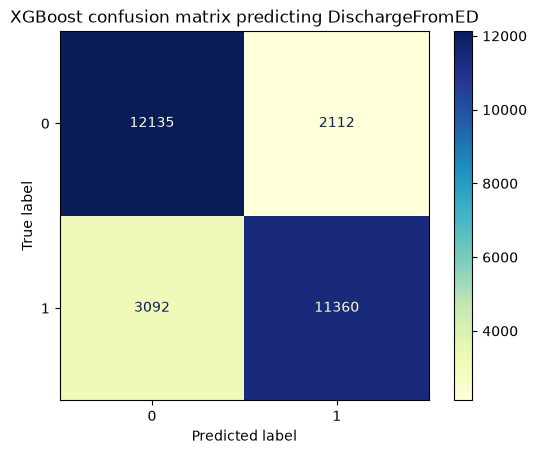

In [82]:
import xgboost as xgb

# Model
xgb = xgb.XGBClassifier(tree_method="hist", early_stopping_rounds=6)

# Training
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)])

# Prediction
y_pred = xgb.predict(X_test)

# Accuracy
print(classification_report(y_test, y_pred))

# Graph
xgb_cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred))
xgb_cm.plot(cmap = 'YlGnBu')
plt.title('XGBoost confusion matrix predicting DischargeFromED')
plt.show()